## Pre-procesammiento y Entrenamiento del Dataset

1. Instalación de librerías

In [1]:
!pip install -q imbalanced-learn catboost

2. Importación de librerías

In [2]:
import os, json, shutil, platform, datetime
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest

import sklearn, catboost
from google.colab import drive
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, roc_curve, auc, roc_auc_score, precision_recall_curve,
                             average_precision_score, brier_score_loss)
from catboost import CatBoostClassifier

SEED = 42
os.makedirs('resultados', exist_ok=True)
os.makedirs('modelos', exist_ok=True)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)

3. Conectar Google Drive

In [3]:
drive.mount('/content/drive')
ruta_archivo = '/content/drive/MyDrive/dataset_ml_entrenamiento_combinado.csv'
print("Cargando dataset...")
df = pd.read_csv(ruta_archivo)

Mounted at /content/drive
Cargando dataset...


4. Diagrama del pipeline

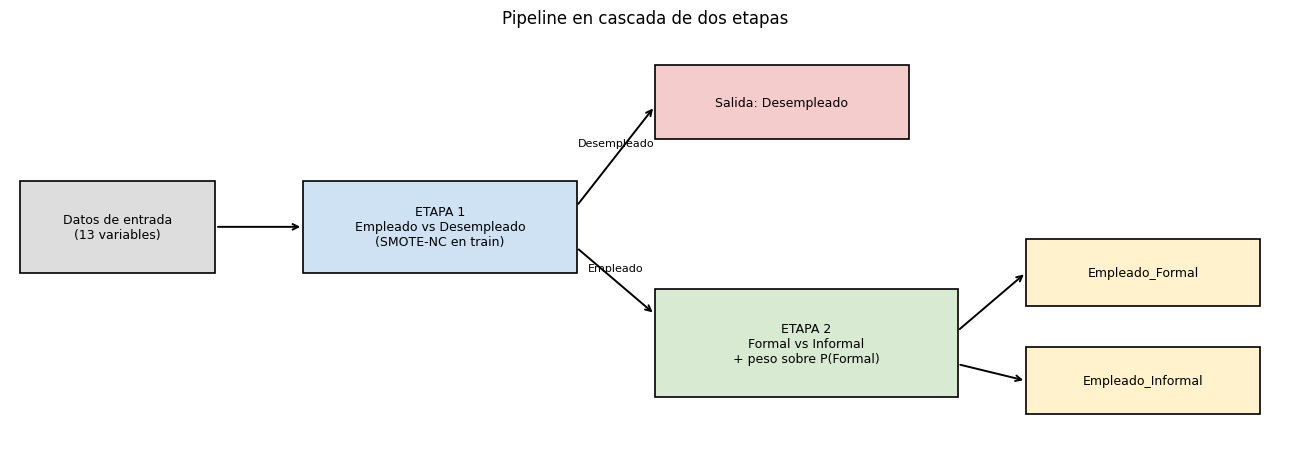

In [4]:
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.set_xlim(0, 13); ax.set_ylim(-0.3, 4.6); ax.axis('off')

def caja(x, y, w, h, txt, color):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=color, ec='black', lw=1.2, zorder=2))
    ax.text(x + w/2, y + h/2, txt, ha='center', va='center', fontsize=9, zorder=3)

def flecha(x1, y1, x2, y2, txt=''):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->', lw=1.4), zorder=1)
    if txt:
        ax.text((x1 + x2)/2, (y1 + y2)/2 + 0.12, txt, ha='center', fontsize=8)

caja(0.1, 1.7, 2.0, 1.1, 'Datos de entrada\n(13 variables)', '#dddddd')
caja(3.0, 1.7, 2.8, 1.1, 'ETAPA 1\nEmpleado vs Desempleado\n(SMOTE-NC en train)', '#cfe2f3')
caja(6.6, 3.3, 2.6, 0.9, 'Salida: Desempleado', '#f4cccc')
caja(6.6, 0.2, 3.1, 1.3, 'ETAPA 2\nFormal vs Informal\n+ peso sobre P(Formal)', '#d9ead3')
caja(10.4, 1.3, 2.4, 0.8, 'Empleado_Formal', '#fff2cc')
caja(10.4, 0.0, 2.4, 0.8, 'Empleado_Informal', '#fff2cc')

flecha(2.1, 2.25, 3.0, 2.25)
flecha(5.8, 2.5, 6.6, 3.7, 'Desempleado')
flecha(5.8, 2.0, 6.6, 1.2, 'Empleado')
flecha(9.7, 1.0, 10.4, 1.7)
flecha(9.7, 0.6, 10.4, 0.4)
ax.set_title('Pipeline en cascada de dos etapas', fontsize=12)
plt.tight_layout()
plt.savefig('resultados/diagrama_pipeline.png', dpi=150)
plt.show()

5. Separación de las características y la variable objetivo

In [5]:
cat_cols = [
    'sexo', 'estado_civil', 'nacionalidad', 'nivel_educ_venezuela',
    'nivel_educ_peru', 'obtuvo_titulo', 'homologo_titulo_peru', 'tipo_permiso_migratorio'
]

num_cols = [
    'edad', 'anios_escolaridad_venezuela', 'anios_escolaridad_peru',
    'brecha_educativa_anios', 'tiempo_residencia_anios'
]

df[cat_cols] = df[cat_cols].astype(str)

# Solo las 13 variables declaradas (si el CSV trae columnas extra, p. ej. 'tiene_carrera_superior',
# CatBoost las usaría aunque los demás modelos no): se descartan y se avisa.
cols_modelo = [c for c in df.columns if c in set(cat_cols + num_cols)]
extras = [c for c in df.columns if c not in cols_modelo + ['condicion_laboral', 'fuente']]
assert len(cols_modelo) == 13, f'Se esperaban 13 variables y hay {len(cols_modelo)}'
print('Columnas del CSV NO usadas como variables:', extras)
assert 'tiene_carrera_superior' not in cols_modelo
X = df[cols_modelo].copy()
y = df['condicion_laboral']

cat_indices = [X.columns.get_loc(col) for col in cat_cols]

print('\nRangos originales de las numéricas (sin recortar):')
print(df[num_cols].describe().T[['min', '50%', 'max']])
print(f"\nDistribución ORIGINAL del Target (Total: {len(y)} registros):")
print(y.value_counts())
print("-" * 50)

Columnas del CSV NO usadas como variables: []

Rangos originales de las numéricas (sin recortar):
                              min   50%   max
edad                         14.0  31.0  78.0
anios_escolaridad_venezuela   0.0  11.0  18.0
anios_escolaridad_peru        0.0  11.0  19.0
brecha_educativa_anios      -19.0   0.0   3.5
tiempo_residencia_anios       0.0   4.0  26.0

Distribución ORIGINAL del Target (Total: 11069 registros):
condicion_laboral
Empleado_Informal    8640
Empleado_Formal      1262
Desempleado          1167
Name: count, dtype: int64
--------------------------------------------------


In [6]:
print(X[cat_cols].dtypes)
print(X['nivel_educ_peru'].unique()[:10])

sexo                       object
estado_civil               object
nacionalidad               object
nivel_educ_venezuela       object
nivel_educ_peru            object
obtuvo_titulo              object
homologo_titulo_peru       object
tipo_permiso_migratorio    object
dtype: object
['13.0' '6.0' '5.0' '10.0' '3.0' '9.0' '4.0' '7.0' '11.0' '1.0']


6. División Train/Test

In [7]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
)

print("Train:", len(y_train), " Val:", len(y_val), " Test:", len(y_test))
print("\nDistribución train:\n", y_train.value_counts())
print("\nDistribución val:\n", y_val.value_counts())
print("\nDistribución test:\n", y_test.value_counts())

# ---------------------------------------------------------------------------
# 6b. Imputación (y winsorización opcional) ajustadas SOLO con train.
# La mediana sale de train y se aplica a val y test (sin fuga de información).
# Está en la MISMA celda que el split a propósito: si se vuelve a dividir, se vuelve a imputar.
# El filtro de edad se aplicó antes, al construir el dataset; no se recortan valores por defecto.
# ---------------------------------------------------------------------------
WINSORIZAR = False   # True = recortar a p1-p99 de TRAIN. No recomendado: reemplaza valores reales por el límite.

print('Nulos en numéricas -> train:', X_train[num_cols].isna().sum().sum(),
      '| val:', X_val[num_cols].isna().sum().sum(), '| test:', X_test[num_cols].isna().sum().sum())
print(X_train[num_cols].isna().sum().rename('nulos en train')[lambda s: s > 0])

medianas_train = X_train[num_cols].median()
lim_inf = X_train[num_cols].quantile(0.01)
lim_sup = X_train[num_cols].quantile(0.99)

def prepro_numericas(Xd):
    Xd = Xd.copy()
    Xd[num_cols] = Xd[num_cols].fillna(medianas_train)
    if WINSORIZAR:
        Xd[num_cols] = Xd[num_cols].clip(lower=lim_inf, upper=lim_sup, axis=1)
    return Xd

X_train, X_val, X_test = prepro_numericas(X_train), prepro_numericas(X_val), prepro_numericas(X_test)
print('Medianas (train):'); print(medianas_train.round(2))
assert X_train[num_cols].isna().sum().sum() == 0 and X_val[num_cols].isna().sum().sum() == 0 and X_test[num_cols].isna().sum().sum() == 0

Train: 6641  Val: 2214  Test: 2214

Distribución train:
 condicion_laboral
Empleado_Informal    5184
Empleado_Formal       757
Desempleado           700
Name: count, dtype: int64

Distribución val:
 condicion_laboral
Empleado_Informal    1728
Empleado_Formal       252
Desempleado           234
Name: count, dtype: int64

Distribución test:
 condicion_laboral
Empleado_Informal    1728
Empleado_Formal       253
Desempleado           233
Name: count, dtype: int64
Nulos en numéricas -> train: 18 | val: 6 | test: 0
anios_escolaridad_venezuela     2
anios_escolaridad_peru          2
brecha_educativa_anios          2
tiempo_residencia_anios        12
Name: nulos en train, dtype: int64
Medianas (train):
edad                           31.0
anios_escolaridad_venezuela    11.0
anios_escolaridad_peru         11.0
brecha_educativa_anios          0.0
tiempo_residencia_anios         4.0
dtype: float64


A) Etapa 1 (Empleado vs Desempleado)

In [8]:
def a_etapa1(serie):
    return serie.apply(lambda x: 'Desempleado' if x == 'Desempleado' else 'Empleado')

y_train_e1 = a_etapa1(y_train)
y_val_e1   = a_etapa1(y_val)
y_test_e1  = a_etapa1(y_test)

print(y_train_e1.value_counts())

condicion_laboral
Empleado       5941
Desempleado     700
Name: count, dtype: int64


B) Etapa 2 (Empleado Formal vs Empleado Informal)

In [9]:
mask_train_emp = y_train != 'Desempleado'
mask_val_emp   = y_val != 'Desempleado'

X_train_e2 = X_train[mask_train_emp]
y_train_e2 = y_train[mask_train_emp]
X_val_e2   = X_val[mask_val_emp]
y_val_e2   = y_val[mask_val_emp]

print(y_train_e2.value_counts())

condicion_laboral
Empleado_Informal    5184
Empleado_Formal       757
Name: count, dtype: int64


7. Preprocesamiento

A) Aplicación de SMOTE-NC al conjunto de entrenamiento

In [10]:
smote_e1 = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_e1_res, y_train_e1_res = smote_e1.fit_resample(X_train, y_train_e1)

In [11]:
smote_e2 = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_e2_res, y_train_e2_res = smote_e2.fit_resample(X_train_e2, y_train_e2)

B) Preprocesamiento

In [12]:
assert not X_val[num_cols].isna().any().any(), 'Hay NaN en X_val: vuelve a ejecutar la celda del split/imputación (sección 6) y luego las siguientes, en orden.'
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

preprocessor_e1 = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

X_train_e1_proc = preprocessor_e1.fit_transform(X_train_e1_res)
X_val_e1_proc   = preprocessor_e1.transform(X_val)

le_e1 = LabelEncoder()
y_train_e1_enc = le_e1.fit_transform(y_train_e1_res)
y_val_e1_enc   = le_e1.transform(y_val_e1)
print("Clases Etapa 1:", list(le_e1.classes_))

Clases Etapa 1: ['Desempleado', 'Empleado']


In [13]:
assert not X_val_e2[num_cols].isna().any().any(), 'Hay NaN en X_val_e2: vuelve a ejecutar la celda del split/imputación (sección 6) y luego las siguientes, en orden.'
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

preprocessor_e2 = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

X_train_e2_proc = preprocessor_e2.fit_transform(X_train_e2_res)
X_val_e2_proc   = preprocessor_e2.transform(X_val_e2)

le_e2 = LabelEncoder()
y_train_e2_enc = le_e2.fit_transform(y_train_e2_res)
y_val_e2_enc   = le_e2.transform(y_val_e2)

print("Clases Etapa 2:", list(le_e2.classes_))

Clases Etapa 2: ['Empleado_Formal', 'Empleado_Informal']


C) Matriz de variables procesadas

In [14]:
def matriz_variables(prep, etapa):
    ohe = prep.named_transformers_['cat']
    n_ohe = dict(zip(cat_cols, [len(c) for c in ohe.categories_]))
    filas = []
    for c in num_cols:
        filas.append({'Etapa': etapa, 'Variable': c, 'Tipo': 'numérica',
                      'LR / DT / RF / SVM': 'StandardScaler', 'Columnas resultantes': 1,
                      'CatBoost': 'Sin transformar'})
    for c in cat_cols:
        filas.append({'Etapa': etapa, 'Variable': c, 'Tipo': 'categórica',
                      'LR / DT / RF / SVM': 'OneHotEncoder', 'Columnas resultantes': n_ohe[c],
                      'CatBoost': 'Categórica nativa (cat_features)'})
    return pd.DataFrame(filas)

matriz_vars = pd.concat([matriz_variables(preprocessor_e1, 'E1'),
                         matriz_variables(preprocessor_e2, 'E2')], ignore_index=True)
display(matriz_vars)
print('Columnas totales tras el ColumnTransformer -> E1:', len(preprocessor_e1.get_feature_names_out()),
      '| E2:', len(preprocessor_e2.get_feature_names_out()))
matriz_vars.to_csv('resultados/a2_2_matriz_variables_procesadas.csv', index=False)
pd.Series(preprocessor_e1.get_feature_names_out(), name='columna').to_csv(
    'resultados/a2_2_columnas_procesadas_e1.csv', index=False)

,Etapa,Variable,Tipo,LR / DT / RF / SVM,Columnas resultantes,CatBoost
0,E1,edad,numérica,StandardScaler,1,Sin transformar
1,E1,anios_escolaridad_venezuela,numérica,StandardScaler,1,Sin transformar
2,E1,anios_escolaridad_peru,numérica,StandardScaler,1,Sin transformar
3,E1,brecha_educativa_anios,numérica,StandardScaler,1,Sin transformar
4,E1,tiempo_residencia_anios,numérica,StandardScaler,1,Sin transformar
5,E1,sexo,categórica,OneHotEncoder,2,Categórica nativa (cat_features)
6,E1,estado_civil,categórica,OneHotEncoder,6,Categórica nativa (cat_features)
7,E1,nacionalidad,categórica,OneHotEncoder,3,Categórica nativa (cat_features)
8,E1,nivel_educ_venezuela,categórica,OneHotEncoder,12,Categórica nativa (cat_features)
9,E1,nivel_educ_peru,categórica,OneHotEncoder,12,Categórica nativa (cat_features)


Columnas totales tras el ColumnTransformer -> E1: 56 | E2: 56


D) Entrenamiento

In [15]:
resultados_e1 = {}
resultados_e2 = {}

*   Regresión Logística

In [16]:
param_dist_lr = {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear']}
rs_lr_e1 = RandomizedSearchCV(LogisticRegression(random_state=42, max_iter=1000),
                               param_dist_lr, n_iter=5, cv=3, scoring='f1_macro', random_state=42, n_jobs=-1)
rs_lr_e1.fit(X_train_e1_proc, y_train_e1_enc)
best_lr_e1 = rs_lr_e1.best_estimator_
pred_lr_e1 = best_lr_e1.predict(X_val_e1_proc)
print("REGRESIÓN LOGÍSTICA - ETAPA 1\n", classification_report(y_val_e1_enc, pred_lr_e1, target_names=le_e1.classes_))
resultados_e1['Reg. Logística'] = classification_report(y_val_e1_enc, pred_lr_e1, target_names=le_e1.classes_, output_dict=True)['macro avg']['f1-score']

REGRESIÓN LOGÍSTICA - ETAPA 1
               precision    recall  f1-score   support

 Desempleado       0.17      0.55      0.26       234
    Empleado       0.93      0.69      0.79      1980

    accuracy                           0.68      2214
   macro avg       0.55      0.62      0.53      2214
weighted avg       0.85      0.68      0.74      2214



In [17]:
param_dist_lr_e2 = {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear']}
rs_lr_e2 = RandomizedSearchCV(
    LogisticRegression(random_state=42, max_iter=1000),
    param_dist_lr_e2, n_iter=5, cv=3, scoring='f1_macro', random_state=42, n_jobs=-1
)
rs_lr_e2.fit(X_train_e2_proc, y_train_e2_enc)
best_lr_e2 = rs_lr_e2.best_estimator_
pred_lr_e2 = best_lr_e2.predict(X_val_e2_proc)
print("=== REGRESIÓN LOGÍSTICA - ETAPA 2 ===")
print(classification_report(y_val_e2_enc, pred_lr_e2, target_names=le_e2.classes_))
resultados_e2['Reg. Logística'] = classification_report(y_val_e2_enc, pred_lr_e2, target_names=le_e2.classes_, output_dict=True)['macro avg']['f1-score']

=== REGRESIÓN LOGÍSTICA - ETAPA 2 ===
                   precision    recall  f1-score   support

  Empleado_Formal       0.23      0.70      0.35       252
Empleado_Informal       0.94      0.66      0.77      1728

         accuracy                           0.66      1980
        macro avg       0.58      0.68      0.56      1980
     weighted avg       0.85      0.66      0.72      1980



*   Árbol de Decisión

In [18]:
param_dist_tree = {'max_depth': [5, 10, 15, 20], 'min_samples_split': [2, 5, 10, 20], 'criterion': ['gini', 'entropy']}
rs_tree_e1 = RandomizedSearchCV(DecisionTreeClassifier(random_state=42),
                                 param_dist_tree, n_iter=10, cv=3, scoring='f1_macro', random_state=42, n_jobs=-1)
rs_tree_e1.fit(X_train_e1_proc, y_train_e1_enc)
best_tree_e1 = rs_tree_e1.best_estimator_
pred_tree_e1 = best_tree_e1.predict(X_val_e1_proc)
print("ÁRBOL DE DECISIÓN - ETAPA 1\n", classification_report(y_val_e1_enc, pred_tree_e1, target_names=le_e1.classes_))
resultados_e1['Árbol Decisión'] = classification_report(y_val_e1_enc, pred_tree_e1, target_names=le_e1.classes_, output_dict=True)['macro avg']['f1-score']

ÁRBOL DE DECISIÓN - ETAPA 1
               precision    recall  f1-score   support

 Desempleado       0.20      0.27      0.23       234
    Empleado       0.91      0.87      0.89      1980

    accuracy                           0.81      2214
   macro avg       0.55      0.57      0.56      2214
weighted avg       0.84      0.81      0.82      2214



In [19]:
param_dist_tree_e2 = {'max_depth': [5, 10, 15, 20], 'min_samples_split': [2, 5, 10, 20], 'criterion': ['gini', 'entropy']}
rs_tree_e2 = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_dist_tree_e2, n_iter=10, cv=3, scoring='f1_macro', random_state=42, n_jobs=-1
)
rs_tree_e2.fit(X_train_e2_proc, y_train_e2_enc)
best_tree_e2 = rs_tree_e2.best_estimator_
pred_tree_e2 = best_tree_e2.predict(X_val_e2_proc)
print("=== ÁRBOL DE DECISIÓN - ETAPA 2 ===")
print(classification_report(y_val_e2_enc, pred_tree_e2, target_names=le_e2.classes_))
resultados_e2['Árbol Decisión'] = classification_report(y_val_e2_enc, pred_tree_e2, target_names=le_e2.classes_, output_dict=True)['macro avg']['f1-score']

=== ÁRBOL DE DECISIÓN - ETAPA 2 ===
                   precision    recall  f1-score   support

  Empleado_Formal       0.24      0.35      0.29       252
Empleado_Informal       0.90      0.84      0.87      1728

         accuracy                           0.78      1980
        macro avg       0.57      0.59      0.58      1980
     weighted avg       0.81      0.78      0.79      1980



*   Random Forest

In [20]:
param_dist_rf = {'n_estimators': [100, 300, 500], 'max_depth': [10, 20, 30, None],
                  'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}
rs_rf_e1 = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                               param_dist_rf, n_iter=15, cv=3, scoring='f1_macro', random_state=42, n_jobs=-1)
rs_rf_e1.fit(X_train_e1_proc, y_train_e1_enc)
best_rf_e1 = rs_rf_e1.best_estimator_
pred_rf_e1 = best_rf_e1.predict(X_val_e1_proc)
print("RANDOM FOREST - ETAPA 1\n", classification_report(y_val_e1_enc, pred_rf_e1, target_names=le_e1.classes_))
resultados_e1['Random Forest'] = classification_report(y_val_e1_enc, pred_rf_e1, target_names=le_e1.classes_, output_dict=True)['macro avg']['f1-score']

RANDOM FOREST - ETAPA 1
               precision    recall  f1-score   support

 Desempleado       0.24      0.23      0.23       234
    Empleado       0.91      0.91      0.91      1980

    accuracy                           0.84      2214
   macro avg       0.57      0.57      0.57      2214
weighted avg       0.84      0.84      0.84      2214



In [21]:
param_dist_rf_e2 = {'n_estimators': [100, 300, 500], 'max_depth': [10, 20, 30, None],
                     'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}
rs_rf_e2 = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_dist_rf_e2, n_iter=15, cv=3, scoring='f1_macro', random_state=42, n_jobs=-1
)
rs_rf_e2.fit(X_train_e2_proc, y_train_e2_enc)
best_rf_e2 = rs_rf_e2.best_estimator_
pred_rf_e2 = best_rf_e2.predict(X_val_e2_proc)
print("=== RANDOM FOREST - ETAPA 2 ===")
print(classification_report(y_val_e2_enc, pred_rf_e2, target_names=le_e2.classes_))
resultados_e2['Random Forest'] = classification_report(y_val_e2_enc, pred_rf_e2, target_names=le_e2.classes_, output_dict=True)['macro avg']['f1-score']

=== RANDOM FOREST - ETAPA 2 ===
                   precision    recall  f1-score   support

  Empleado_Formal       0.31      0.31      0.31       252
Empleado_Informal       0.90      0.90      0.90      1728

         accuracy                           0.82      1980
        macro avg       0.60      0.61      0.60      1980
     weighted avg       0.82      0.82      0.82      1980



*   Support Vector Machine

In [22]:
param_dist_svm = {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}
rs_svm_e1 = RandomizedSearchCV(SVC(random_state=42, probability=True),
                                param_dist_svm, n_iter=3, cv=3, scoring='f1_macro', random_state=42, n_jobs=-1)
rs_svm_e1.fit(X_train_e1_proc, y_train_e1_enc)
best_svm_e1 = rs_svm_e1.best_estimator_
pred_svm_e1 = best_svm_e1.predict(X_val_e1_proc)
print("SVM - ETAPA 1\n", classification_report(y_val_e1_enc, pred_svm_e1, target_names=le_e1.classes_))
resultados_e1['SVM'] = classification_report(y_val_e1_enc, pred_svm_e1, target_names=le_e1.classes_, output_dict=True)['macro avg']['f1-score']

SVM - ETAPA 1
               precision    recall  f1-score   support

 Desempleado       0.20      0.60      0.30       234
    Empleado       0.94      0.71      0.81      1980

    accuracy                           0.70      2214
   macro avg       0.57      0.66      0.55      2214
weighted avg       0.86      0.70      0.75      2214



In [23]:
param_dist_svm_e2 = {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}
rs_svm_e2 = RandomizedSearchCV(
    SVC(random_state=42, probability=True),
    param_dist_svm_e2, n_iter=3, cv=3, scoring='f1_macro', random_state=42, n_jobs=-1
)
rs_svm_e2.fit(X_train_e2_proc, y_train_e2_enc)
best_svm_e2 = rs_svm_e2.best_estimator_
pred_svm_e2 = best_svm_e2.predict(X_val_e2_proc)
print("=== SVM - ETAPA 2 ===")
print(classification_report(y_val_e2_enc, pred_svm_e2, target_names=le_e2.classes_))
resultados_e2['SVM'] = classification_report(y_val_e2_enc, pred_svm_e2, target_names=le_e2.classes_, output_dict=True)['macro avg']['f1-score']

=== SVM - ETAPA 2 ===
                   precision    recall  f1-score   support

  Empleado_Formal       0.22      0.72      0.33       252
Empleado_Informal       0.94      0.62      0.75      1728

         accuracy                           0.63      1980
        macro avg       0.58      0.67      0.54      1980
     weighted avg       0.85      0.63      0.69      1980



*   CatBoost

In [24]:
cat_model_e1 = CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6,
                                    random_seed=42, verbose=0, cat_features=cat_cols)
cat_model_e1.fit(X_train_e1_res, y_train_e1_res)
pred_cat_e1 = cat_model_e1.predict(X_val).ravel()
print("CATBOOST - ETAPA 1\n", classification_report(y_val_e1, pred_cat_e1))
resultados_e1['CatBoost'] = classification_report(y_val_e1, pred_cat_e1, output_dict=True)['macro avg']['f1-score']

CATBOOST - ETAPA 1
               precision    recall  f1-score   support

 Desempleado       0.28      0.22      0.25       234
    Empleado       0.91      0.93      0.92      1980

    accuracy                           0.86      2214
   macro avg       0.59      0.58      0.58      2214
weighted avg       0.84      0.86      0.85      2214



In [25]:
cat_model_e2 = CatBoostClassifier(
    iterations=500, learning_rate=0.05, depth=6,
    random_seed=42, verbose=0, cat_features=cat_cols
)
cat_model_e2.fit(X_train_e2_res, y_train_e2_res)
pred_cat_e2 = cat_model_e2.predict(X_val_e2).ravel()
print("=== CATBOOST - ETAPA 2 ===")
print(classification_report(y_val_e2, pred_cat_e2))
resultados_e2['CatBoost'] = classification_report(y_val_e2, pred_cat_e2, output_dict=True)['macro avg']['f1-score']

=== CATBOOST - ETAPA 2 ===
                   precision    recall  f1-score   support

  Empleado_Formal       0.32      0.33      0.33       252
Empleado_Informal       0.90      0.90      0.90      1728

         accuracy                           0.83      1980
        macro avg       0.61      0.62      0.61      1980
     weighted avg       0.83      0.83      0.83      1980



8. Tabla de espacios de búsqueda y valores óptimos

In [26]:
def filas_hp(rs_dict, etapa):
    return [{'Etapa': etapa, 'Modelo': n, 'Espacio de búsqueda': str(rs.param_distributions),
             'n_iter': rs.n_iter, 'Mejores hiperparámetros': str(rs.best_params_),
             'macro-F1 CV (cv=3)': round(rs.best_score_, 4)} for n, rs in rs_dict.items()]

rs_e1 = {'Reg. Logística': rs_lr_e1, 'Árbol de Decisión': rs_tree_e1, 'Random Forest': rs_rf_e1, 'SVM': rs_svm_e1}
rs_e2 = {'Reg. Logística': rs_lr_e2, 'Árbol de Decisión': rs_tree_e2, 'Random Forest': rs_rf_e2, 'SVM': rs_svm_e2}

def fila_catboost(etapa, modelo):
    p = modelo.get_params()
    fijo = {k: p[k] for k in ('iterations', 'learning_rate', 'depth', 'random_seed') if k in p}
    return {'Etapa': etapa, 'Modelo': 'CatBoost', 'Espacio de búsqueda': '— (configuración fija)',
            'n_iter': '—', 'Mejores hiperparámetros': str(fijo), 'macro-F1 CV (cv=3)': '—'}

tabla_hp = pd.DataFrame(filas_hp(rs_e1, 'E1') + [fila_catboost('E1', cat_model_e1)] +
                        filas_hp(rs_e2, 'E2') + [fila_catboost('E2', cat_model_e2)])
display(tabla_hp)
tabla_hp.to_csv('resultados/a2_3_hiperparametros.csv', index=False)

,Etapa,Modelo,Espacio de búsqueda,n_iter,Mejores hiperparámetros,macro-F1 CV (cv=3)
0,E1,Reg. Logística,"{'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear']}",5,"{'solver': 'lbfgs', 'C': 100}",0.7387
1,E1,Árbol de Decisión,"{'max_depth': [5, 10, 15, 20], 'min_samples_split': [2, 5, 10, 20], 'criterion': ['gini', 'entropy']}",10,"{'min_samples_split': 5, 'max_depth': 20, 'criterion': 'entropy'}",0.863
2,E1,Random Forest,"{'n_estimators': [100, 300, 500], 'max_depth': [10, 20, 30, None], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}",15,"{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}",0.891
3,E1,SVM,"{'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}",3,"{'kernel': 'rbf', 'C': 0.1}",0.7629
4,E1,CatBoost,— (configuración fija),—,"{'iterations': 500, 'learning_rate': 0.05, 'depth': 6, 'random_seed': 42}",—
5,E2,Reg. Logística,"{'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear']}",5,"{'solver': 'liblinear', 'C': 1}",0.751
6,E2,Árbol de Decisión,"{'max_depth': [5, 10, 15, 20], 'min_samples_split': [2, 5, 10, 20], 'criterion': ['gini', 'entropy']}",10,"{'min_samples_split': 2, 'max_depth': 20, 'criterion': 'gini'}",0.8433
7,E2,Random Forest,"{'n_estimators': [100, 300, 500], 'max_depth': [10, 20, 30, None], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}",15,"{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}",0.8684
8,E2,SVM,"{'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}",3,"{'kernel': 'rbf', 'C': 0.1}",0.7437
9,E2,CatBoost,— (configuración fija),—,"{'iterations': 500, 'learning_rate': 0.05, 'depth': 6, 'random_seed': 42}",—


9. Baseline y tabla comparativa por etapa con precision, recall y F1 por clase.

In [27]:
dummy_e1 = DummyClassifier(strategy='most_frequent').fit(X_train, y_train_e1)
dummy_e2 = DummyClassifier(strategy='most_frequent').fit(X_train_e2, y_train_e2)

preds_e1 = {
    'Baseline (mayoritaria)': dummy_e1.predict(X_val),
    'Reg. Logística':    le_e1.inverse_transform(pred_lr_e1),
    'Árbol de Decisión': le_e1.inverse_transform(pred_tree_e1),
    'Random Forest':     le_e1.inverse_transform(pred_rf_e1),
    'SVM':               le_e1.inverse_transform(pred_svm_e1),
    'CatBoost':          np.asarray(pred_cat_e1),
}
preds_e2 = {
    'Baseline (mayoritaria)': dummy_e2.predict(X_val_e2),
    'Reg. Logística':    le_e2.inverse_transform(pred_lr_e2),
    'Árbol de Decisión': le_e2.inverse_transform(pred_tree_e2),
    'Random Forest':     le_e2.inverse_transform(pred_rf_e2),
    'SVM':               le_e2.inverse_transform(pred_svm_e2),
    'CatBoost':          np.asarray(pred_cat_e2),
}

def reporte_largo(etapa, modelo, y_true, y_pred):
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    return [{'Etapa': etapa, 'Modelo': modelo, 'Clase': clase, 'Precision': m['precision'],
             'Recall': m['recall'], 'F1': m['f1-score'], 'Soporte': int(m['support'])}
            for clase, m in rep.items() if clase not in ('accuracy', 'weighted avg')]

filas = []
for n, p in preds_e1.items(): filas += reporte_largo('E1', n, y_val_e1.values, p)
for n, p in preds_e2.items(): filas += reporte_largo('E2', n, y_val_e2.values, p)
tabla_comparativa = pd.DataFrame(filas)
tabla_comparativa.to_csv('resultados/a2_4_comparativa_validacion.csv', index=False)

for e in ('E1', 'E2'):
    print(f'\n===== {e}: precision / recall / F1 por clase (validación) =====')
    display(tabla_comparativa[tabla_comparativa.Etapa == e].drop(columns='Etapa').round(3))

print('\n===== Ranking por macro-F1 (validación) =====')
ranking = (tabla_comparativa[tabla_comparativa.Clase == 'macro avg']
           [['Etapa', 'Modelo', 'Precision', 'Recall', 'F1']]
           .rename(columns={'F1': 'macro-F1'}).sort_values(['Etapa', 'macro-F1'], ascending=[True, False]))
display(ranking.round(3))
ranking.to_csv('resultados/a2_5_ranking_macro_f1_con_baseline.csv', index=False)


===== E1: precision / recall / F1 por clase (validación) =====


,Modelo,Clase,Precision,Recall,F1,Soporte
0,Baseline (mayoritaria),Desempleado,0.000,0.000,0.000,234
1,Baseline (mayoritaria),Empleado,0.894,1.000,0.944,1980
2,Baseline (mayoritaria),macro avg,0.447,0.500,0.472,2214
3,Reg. Logística,Desempleado,0.174,0.551,0.265,234
4,Reg. Logística,Empleado,0.929,0.691,0.793,1980
5,Reg. Logística,macro avg,0.552,0.621,0.529,2214
6,Árbol de Decisión,Desempleado,0.199,0.274,0.231,234
7,Árbol de Decisión,Empleado,0.910,0.870,0.890,1980
8,Árbol de Decisión,macro avg,0.555,0.572,0.560,2214
9,Random Forest,Desempleado,0.236,0.226,0.231,234



===== E2: precision / recall / F1 por clase (validación) =====


,Modelo,Clase,Precision,Recall,F1,Soporte
18,Baseline (mayoritaria),Empleado_Formal,0.000,0.000,0.000,252
19,Baseline (mayoritaria),Empleado_Informal,0.873,1.000,0.932,1728
20,Baseline (mayoritaria),macro avg,0.436,0.500,0.466,1980
21,Reg. Logística,Empleado_Formal,0.230,0.702,0.347,252
22,Reg. Logística,Empleado_Informal,0.938,0.657,0.773,1728
23,Reg. Logística,macro avg,0.584,0.680,0.560,1980
24,Árbol de Decisión,Empleado_Formal,0.241,0.349,0.285,252
25,Árbol de Decisión,Empleado_Informal,0.898,0.840,0.868,1728
26,Árbol de Decisión,macro avg,0.570,0.594,0.577,1980
27,Random Forest,Empleado_Formal,0.307,0.313,0.310,252



===== Ranking por macro-F1 (validación) =====


,Etapa,Modelo,Precision,Recall,macro-F1
17,E1,CatBoost,0.594,0.577,0.584
11,E1,Random Forest,0.572,0.570,0.571
8,E1,Árbol de Decisión,0.555,0.572,0.560
14,E1,SVM,0.567,0.656,0.552
5,E1,Reg. Logística,0.552,0.621,0.529
2,E1,Baseline (mayoritaria),0.447,0.500,0.472
35,E2,CatBoost,0.613,0.616,0.615
29,E2,Random Forest,0.603,0.605,0.604
26,E2,Árbol de Decisión,0.570,0.594,0.577
23,E2,Reg. Logística,0.584,0.680,0.560


10. Análisis de Resultados

A) Etapa 1

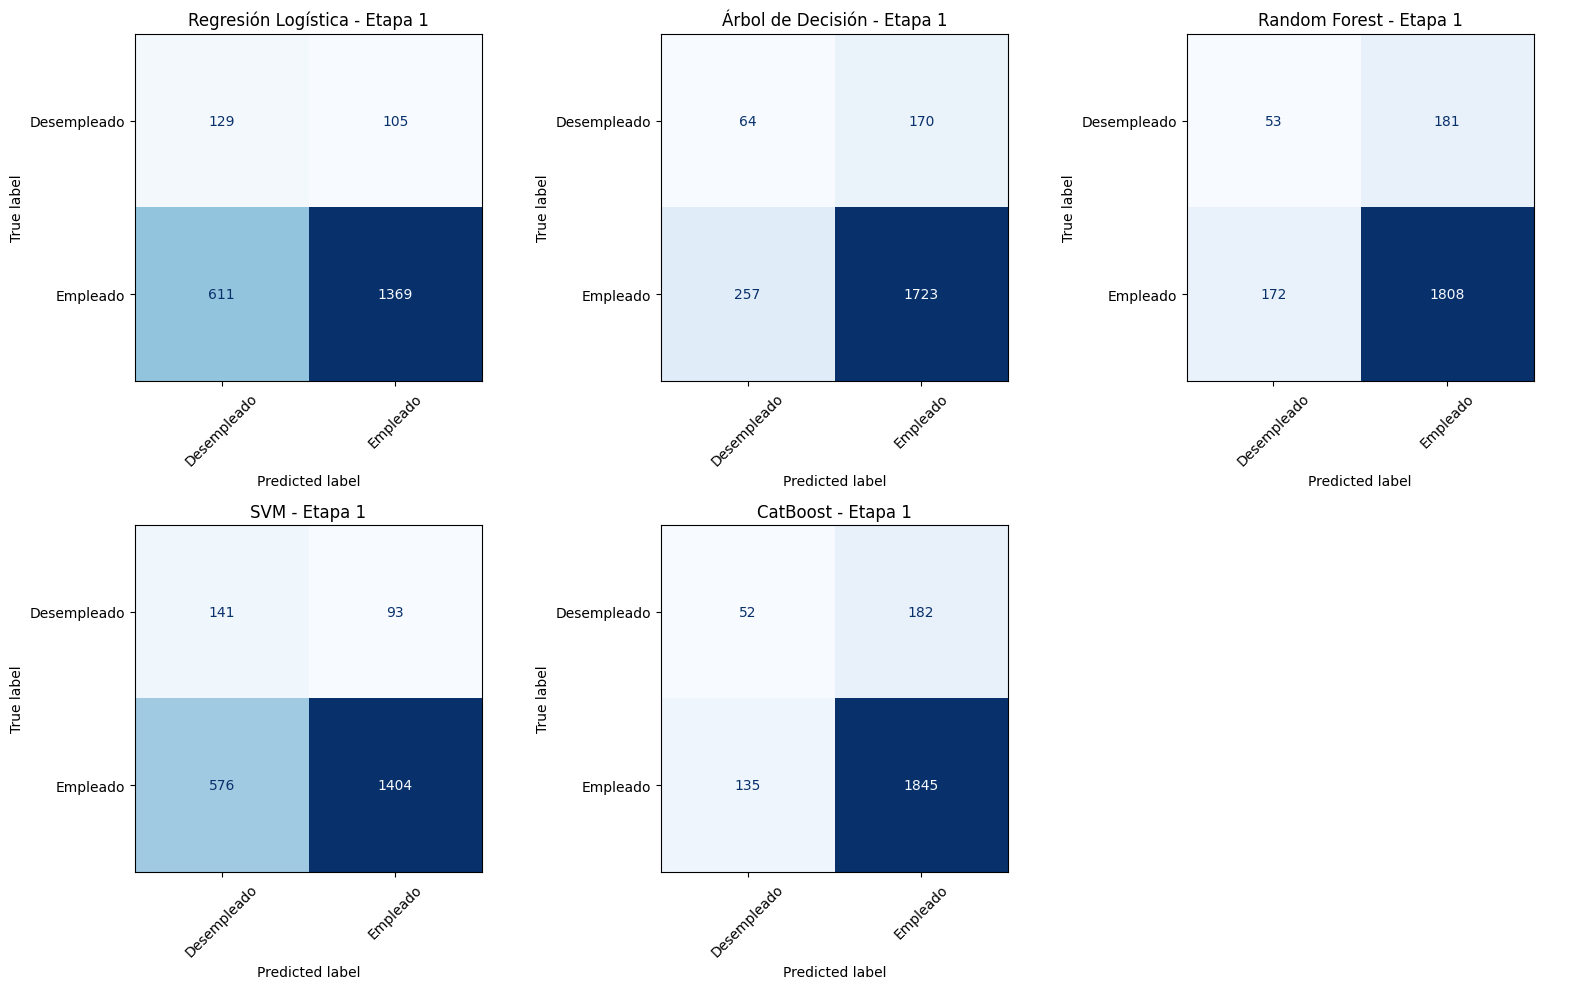

In [28]:
modelos_preds_e1 = [
    ('Regresión Logística', pred_lr_e1, y_val_e1_enc, le_e1.classes_),
    ('Árbol de Decisión',   pred_tree_e1, y_val_e1_enc, le_e1.classes_),
    ('Random Forest',       pred_rf_e1, y_val_e1_enc, le_e1.classes_),
    ('SVM',                 pred_svm_e1, y_val_e1_enc, le_e1.classes_),
    ('CatBoost',            pred_cat_e1, y_val_e1, sorted(y_val_e1.unique())),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (nombre, pred, y_true, labels) in enumerate(modelos_preds_e1):
    cm = confusion_matrix(y_true, pred)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=axes[i], cmap='Blues', xticks_rotation=45, colorbar=False)
    axes[i].set_title(f"{nombre} - Etapa 1")

axes[-1].axis('off')
plt.tight_layout()
plt.savefig('resultados/matrices_confusion_etapa1.png', dpi=150)
plt.show()

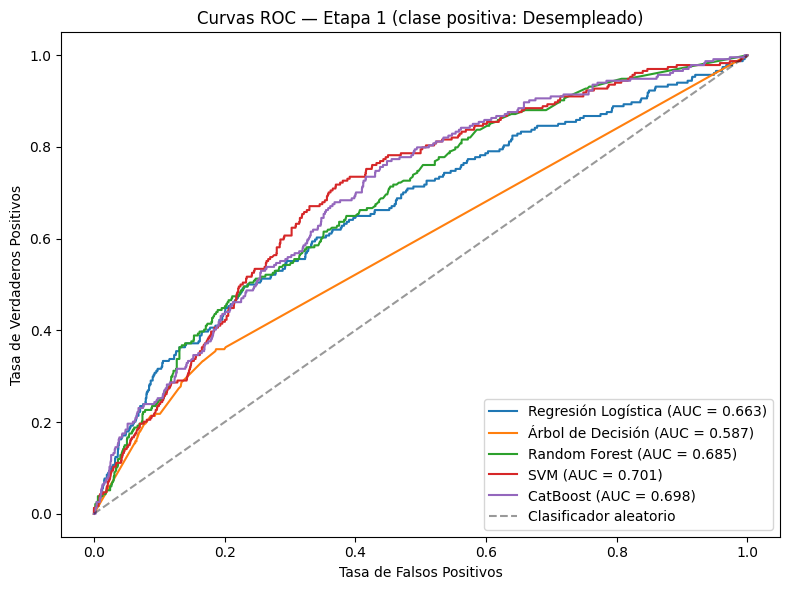

In [29]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import numpy as np

modelos_e1 = {
    'Regresión Logística': (best_lr_e1, X_val_e1_proc, y_val_e1_enc),
    'Árbol de Decisión':   (best_tree_e1, X_val_e1_proc, y_val_e1_enc),
    'Random Forest':       (best_rf_e1, X_val_e1_proc, y_val_e1_enc),
    'SVM':                 (best_svm_e1, X_val_e1_proc, y_val_e1_enc),
}

idx_desempleado_le = list(le_e1.classes_).index('Desempleado')

plt.figure(figsize=(8, 6))

for nombre, (modelo, X, y_true) in modelos_e1.items():
    probs = modelo.predict_proba(X)[:, idx_desempleado_le]
    y_true_bin = (y_true == idx_desempleado_le).astype(int)
    fpr, tpr, _ = roc_curve(y_true_bin, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc:.3f})')

probs_cat_e1 = cat_model_e1.predict_proba(X_val)
idx_desempleado_cat = list(cat_model_e1.classes_).index('Desempleado')
y_val_e1_bin = (y_val_e1 == 'Desempleado').astype(int)
fpr_cat, tpr_cat, _ = roc_curve(y_val_e1_bin, probs_cat_e1[:, idx_desempleado_cat])
roc_auc_cat = auc(fpr_cat, tpr_cat)
plt.plot(fpr_cat, tpr_cat, label=f'CatBoost (AUC = {roc_auc_cat:.3f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Clasificador aleatorio')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curvas ROC — Etapa 1 (clase positiva: Desempleado)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('resultados/roc_etapa1.png', dpi=150)
plt.show()

B) Etapa 2

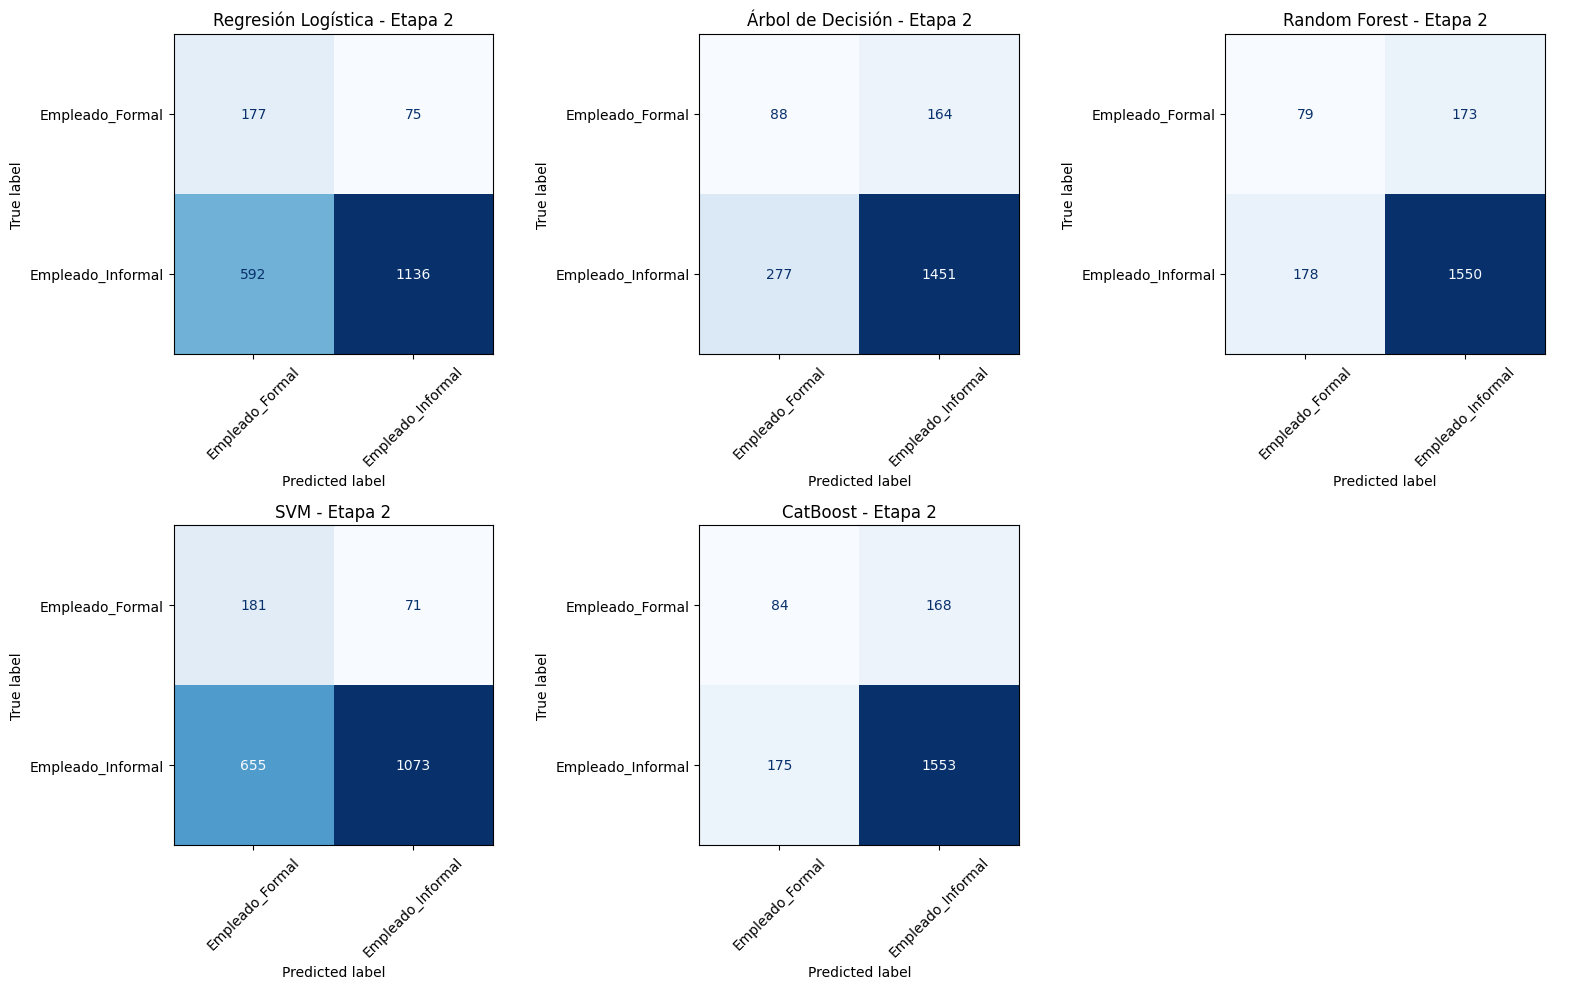

In [30]:
modelos_preds_e2 = [
    ('Regresión Logística', pred_lr_e2, y_val_e2_enc, le_e2.classes_),
    ('Árbol de Decisión',   pred_tree_e2, y_val_e2_enc, le_e2.classes_),
    ('Random Forest',       pred_rf_e2, y_val_e2_enc, le_e2.classes_),
    ('SVM',                 pred_svm_e2, y_val_e2_enc, le_e2.classes_),
    ('CatBoost',            pred_cat_e2, y_val_e2, sorted(y_val_e2.unique())),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (nombre, pred, y_true, labels) in enumerate(modelos_preds_e2):
    cm = confusion_matrix(y_true, pred)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=axes[i], cmap='Blues', xticks_rotation=45, colorbar=False)
    axes[i].set_title(f"{nombre} - Etapa 2")

axes[-1].axis('off')
plt.tight_layout()
plt.savefig('resultados/matrices_confusion_etapa2.png', dpi=150)
plt.show()

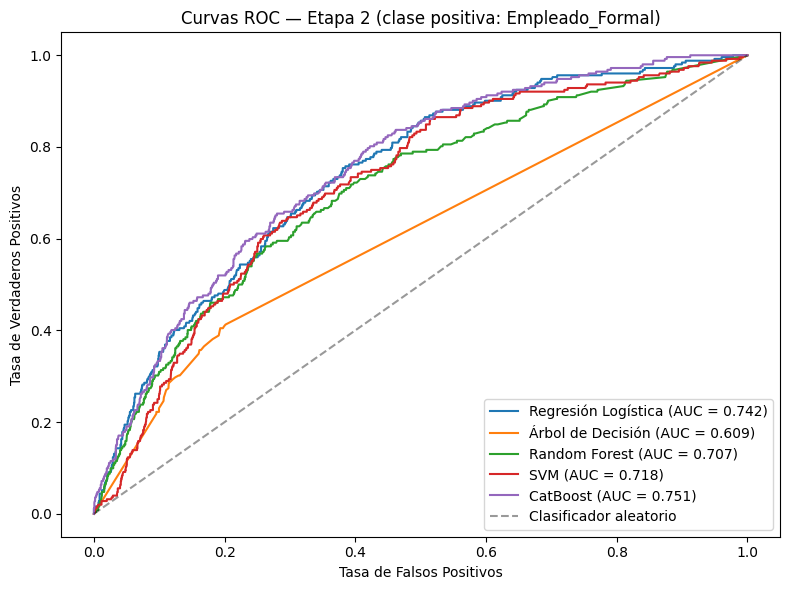

In [31]:
modelos_e2 = {
    'Regresión Logística': (best_lr_e2, X_val_e2_proc, y_val_e2_enc),
    'Árbol de Decisión':   (best_tree_e2, X_val_e2_proc, y_val_e2_enc),
    'Random Forest':       (best_rf_e2, X_val_e2_proc, y_val_e2_enc),
    'SVM':                 (best_svm_e2, X_val_e2_proc, y_val_e2_enc),
}

idx_formal_le = list(le_e2.classes_).index('Empleado_Formal')

plt.figure(figsize=(8, 6))

for nombre, (modelo, X, y_true) in modelos_e2.items():
    probs = modelo.predict_proba(X)[:, idx_formal_le]
    y_true_bin = (y_true == idx_formal_le).astype(int)
    fpr, tpr, _ = roc_curve(y_true_bin, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc:.3f})')

probs_cat_e2 = cat_model_e2.predict_proba(X_val_e2)
idx_formal_cat = list(cat_model_e2.classes_).index('Empleado_Formal')
y_val_e2_bin = (y_val_e2 == 'Empleado_Formal').astype(int)
fpr_cat, tpr_cat, _ = roc_curve(y_val_e2_bin, probs_cat_e2[:, idx_formal_cat])
roc_auc_cat = auc(fpr_cat, tpr_cat)
plt.plot(fpr_cat, tpr_cat, label=f'CatBoost (AUC = {roc_auc_cat:.3f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Clasificador aleatorio')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curvas ROC — Etapa 2 (clase positiva: Empleado_Formal)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('resultados/roc_etapa2.png', dpi=150)
plt.show()

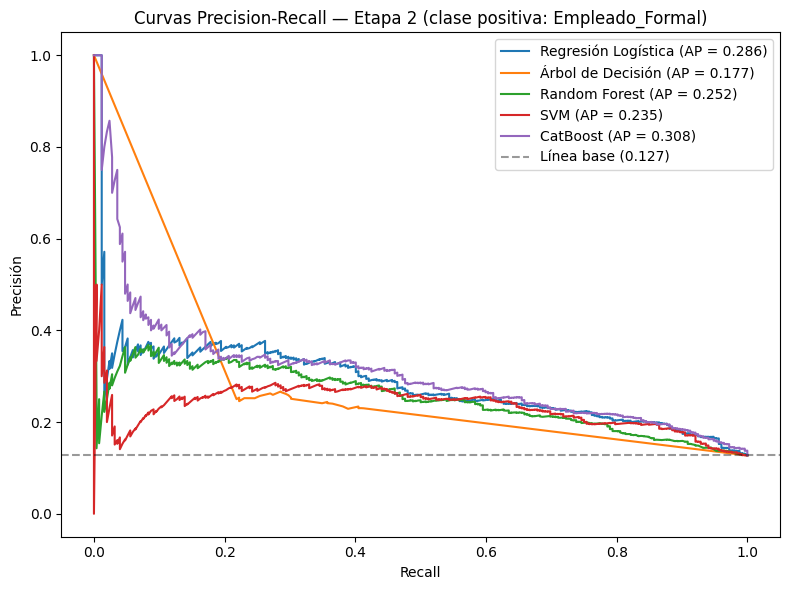

In [32]:
plt.figure(figsize=(8, 6))

for nombre, (modelo, X, y_true) in modelos_e2.items():
    probs = modelo.predict_proba(X)[:, idx_formal_le]
    y_true_bin = (y_true == idx_formal_le).astype(int)
    precision, recall, _ = precision_recall_curve(y_true_bin, probs)
    ap = average_precision_score(y_true_bin, probs)
    plt.plot(recall, precision, label=f'{nombre} (AP = {ap:.3f})')

probs_cat_e2 = cat_model_e2.predict_proba(X_val_e2)
precision_cat, recall_cat, _ = precision_recall_curve(y_val_e2_bin, probs_cat_e2[:, idx_formal_cat])
ap_cat = average_precision_score(y_val_e2_bin, probs_cat_e2[:, idx_formal_cat])
plt.plot(recall_cat, precision_cat, label=f'CatBoost (AP = {ap_cat:.3f})')

base_rate = y_val_e2_bin.mean()
plt.axhline(base_rate, color='k', linestyle='--', alpha=0.4, label=f'Línea base ({base_rate:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precisión')
plt.title('Curvas Precision-Recall — Etapa 2 (clase positiva: Empleado_Formal)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('resultados/pr_etapa2.png', dpi=150)
plt.show()

C) Etapa 1 y Etapa 2

In [33]:
def prob_pos(modelo, X, clase_pos, le=None):
    """Probabilidad de la clase positiva (sklearn con LabelEncoder, o CatBoost con etiquetas de texto)."""
    clases = list(le.classes_) if le is not None else list(modelo.classes_)
    return modelo.predict_proba(X)[:, clases.index(clase_pos)]

sk_e1 = {'Reg. Logística': best_lr_e1, 'Árbol de Decisión': best_tree_e1, 'Random Forest': best_rf_e1, 'SVM': best_svm_e1}
sk_e2 = {'Reg. Logística': best_lr_e2, 'Árbol de Decisión': best_tree_e2, 'Random Forest': best_rf_e2, 'SVM': best_svm_e2}

pos_val_e1 = {n: prob_pos(m, X_val_e1_proc, 'Desempleado', le_e1) for n, m in sk_e1.items()}
pos_val_e1['CatBoost'] = prob_pos(cat_model_e1, X_val, 'Desempleado')
ybin_val_e1 = (y_val_e1.values == 'Desempleado').astype(int)

pos_val_e2 = {n: prob_pos(m, X_val_e2_proc, 'Empleado_Formal', le_e2) for n, m in sk_e2.items()}
pos_val_e2['CatBoost'] = prob_pos(cat_model_e2, X_val_e2, 'Empleado_Formal')
ybin_val_e2 = (y_val_e2.values == 'Empleado_Formal').astype(int)

filas = []
for n, p in pos_val_e1.items():
    filas.append({'Etapa': 'E1 (+ = Desempleado)', 'Modelo': n, 'AUC': roc_auc_score(ybin_val_e1, p),
                  'AP': average_precision_score(ybin_val_e1, p)})
for n, p in pos_val_e2.items():
    filas.append({'Etapa': 'E2 (+ = Formal)', 'Modelo': n, 'AUC': roc_auc_score(ybin_val_e2, p),
                  'AP': average_precision_score(ybin_val_e2, p)})
tabla_auc_ap = pd.DataFrame(filas)
display(tabla_auc_ap.round(3))
print('Prevalencia (AP de un clasificador aleatorio): E1 =', round(ybin_val_e1.mean(), 3),
      '| E2 =', round(ybin_val_e2.mean(), 3))
tabla_auc_ap.to_csv('resultados/a2_6_auc_ap_validacion.csv', index=False)

,Etapa,Modelo,AUC,AP
0,E1 (+ = Desempleado),Reg. Logística,0.663,0.214
1,E1 (+ = Desempleado),Árbol de Decisión,0.587,0.145
2,E1 (+ = Desempleado),Random Forest,0.685,0.201
3,E1 (+ = Desempleado),SVM,0.701,0.210
4,E1 (+ = Desempleado),CatBoost,0.698,0.211
5,E2 (+ = Formal),Reg. Logística,0.742,0.286
6,E2 (+ = Formal),Árbol de Decisión,0.609,0.177
7,E2 (+ = Formal),Random Forest,0.707,0.252
8,E2 (+ = Formal),SVM,0.718,0.235
9,E2 (+ = Formal),CatBoost,0.751,0.308


Prevalencia (AP de un clasificador aleatorio): E1 = 0.106 | E2 = 0.127


11. Grid search de pesos

Orden de clases: ['Empleado_Formal', 'Empleado_Informal']
Mejor peso para Formal: 1.2  |  macro-F1 val: 0.6240
macro-F1 val con peso 1.6: 0.6151  (diferencia vs óptimo: +0.0089)


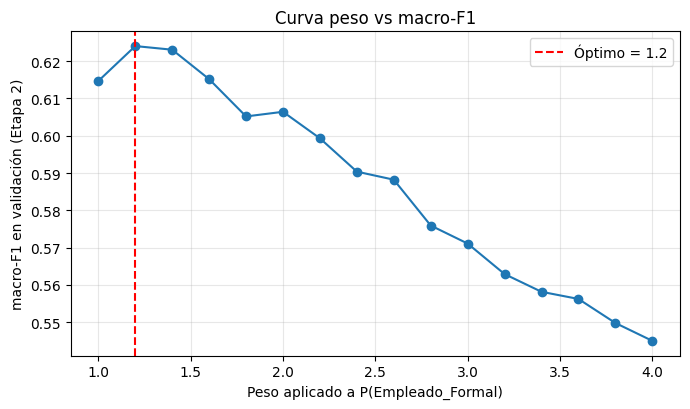

                   precision    recall  f1-score   support

  Empleado_Formal       0.32      0.40      0.36       252
Empleado_Informal       0.91      0.87      0.89      1728

         accuracy                           0.81      1980
        macro avg       0.61      0.64      0.62      1980
     weighted avg       0.83      0.81      0.82      1980



In [34]:
probs_val_e2 = cat_model_e2.predict_proba(X_val_e2)
clases_e2 = list(cat_model_e2.classes_)
idx_formal = clases_e2.index('Empleado_Formal')
print('Orden de clases:', clases_e2)

pesos_grid = np.round(np.arange(1.0, 4.0 + 1e-9, 0.2), 1)

def f1_con_peso(w, probs, y_true):
    p = probs.copy()
    p[:, idx_formal] *= w
    return f1_score(y_true, np.array(clases_e2)[p.argmax(axis=1)], average='macro')

curva_pesos = pd.DataFrame({'peso_formal': pesos_grid,
                            'macro_f1_val': [f1_con_peso(w, probs_val_e2, y_val_e2) for w in pesos_grid]})
fila_opt = curva_pesos.loc[curva_pesos.macro_f1_val.idxmax()]
mejor_peso_formal = float(fila_opt.peso_formal)
mejor_f1 = float(fila_opt.macro_f1_val)
f1_en_16 = float(curva_pesos.loc[curva_pesos.peso_formal == 1.6, 'macro_f1_val'].iloc[0])

print(f'Mejor peso para Formal: {mejor_peso_formal}  |  macro-F1 val: {mejor_f1:.4f}')
print(f'macro-F1 val con peso 1.6: {f1_en_16:.4f}  (diferencia vs óptimo: {mejor_f1 - f1_en_16:+.4f})')

plt.figure(figsize=(7, 4.2))
plt.plot(curva_pesos.peso_formal, curva_pesos.macro_f1_val, marker='o')
plt.axvline(mejor_peso_formal, color='red', ls='--', label=f'Óptimo = {mejor_peso_formal}')
plt.xlabel('Peso aplicado a P(Empleado_Formal)')
plt.ylabel('macro-F1 en validación (Etapa 2)')
plt.title('Curva peso vs macro-F1')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('resultados/a2_7_curva_peso_macro_f1.png', dpi=150)
plt.show()
curva_pesos.to_csv('resultados/a2_7_curva_peso_macro_f1.csv', index=False)

pesos_finales = np.ones(len(clases_e2))
pesos_finales[idx_formal] = mejor_peso_formal
y_pred_final_e2 = np.array(clases_e2)[(probs_val_e2 * pesos_finales).argmax(axis=1)]
print(classification_report(y_val_e2, y_pred_final_e2))

12. Evaluación end-to-end

                   precision    recall  f1-score   support

      Desempleado       0.31      0.29      0.30       233
  Empleado_Formal       0.30      0.42      0.35       253
Empleado_Informal       0.82      0.78      0.80      1728

         accuracy                           0.68      2214
        macro avg       0.47      0.50      0.48      2214
     weighted avg       0.71      0.68      0.69      2214

macro-F1 test (cascada): 0.4810


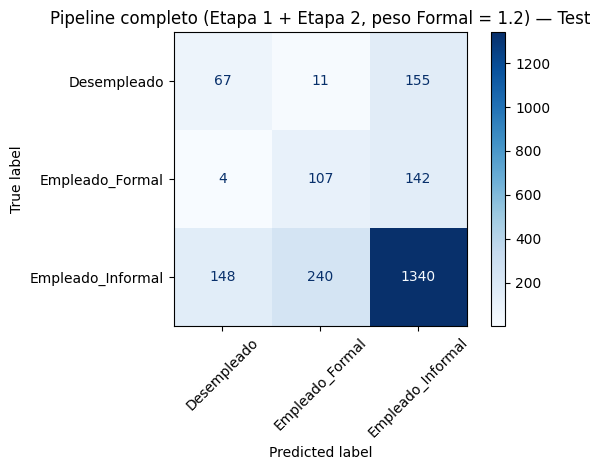

In [35]:
pred_e1_test = cat_model_e1.predict(X_test).ravel()

pred_final = pred_e1_test.astype(object)
idx_empleados = np.where(pred_e1_test == 'Empleado')[0]
probs_e2_test = cat_model_e2.predict_proba(X_test.iloc[idx_empleados]) * pesos_finales
pred_final[idx_empleados] = np.array(clases_e2)[probs_e2_test.argmax(axis=1)]
pred_final = np.asarray(pred_final, dtype=str)

ETIQUETAS = ['Desempleado', 'Empleado_Formal', 'Empleado_Informal']
print(classification_report(y_test, pred_final, labels=ETIQUETAS))
f1_cascada_test = f1_score(y_test, pred_final, labels=ETIQUETAS, average='macro')
print(f'macro-F1 test (cascada): {f1_cascada_test:.4f}')

cm_final = confusion_matrix(y_test, pred_final, labels=ETIQUETAS)
ConfusionMatrixDisplay(cm_final, display_labels=ETIQUETAS).plot(cmap='Blues', xticks_rotation=45)
plt.title(f'Pipeline completo (Etapa 1 + Etapa 2, peso Formal = {mejor_peso_formal}) — Test')
plt.tight_layout()
plt.savefig('resultados/a2_8_matriz_confusion_pipeline_test.png', dpi=150)
plt.show()

pd.DataFrame(classification_report(y_test, pred_final, labels=ETIQUETAS, output_dict=True)).T.to_csv(
    'resultados/a2_8_reporte_test_cascada.csv')

13. Incertidumbre y significancia

In [36]:
CLASES = ['Desempleado', 'Empleado_Formal', 'Empleado_Informal']

X_train_mc_res, y_train_mc_res = SMOTENC(categorical_features=cat_indices, random_state=SEED).fit_resample(X_train, y_train)

preprocessor_mc = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])
X_train_mc_proc = preprocessor_mc.fit_transform(X_train_mc_res)
X_val_mc_proc   = preprocessor_mc.transform(X_val)
X_test_mc_proc  = preprocessor_mc.transform(X_test)

le_mc = LabelEncoder().fit(CLASES)
y_train_mc_enc = le_mc.transform(y_train_mc_res)
y_val_mc_enc   = le_mc.transform(y_val)
y_test_mc_enc  = le_mc.transform(y_test)

espacios_mc = {
    'Reg. Logística':    (LogisticRegression(random_state=SEED, max_iter=1000), {**param_dist_lr, 'solver': ['lbfgs']}, 5),
    'Árbol de Decisión': (DecisionTreeClassifier(random_state=SEED),            param_dist_tree, rs_tree_e1.n_iter),
    'Random Forest':     (RandomForestClassifier(random_state=SEED, n_jobs=-1), param_dist_rf,   rs_rf_e1.n_iter),
    'SVM':               (SVC(random_state=SEED, probability=True),             param_dist_svm,  rs_svm_e1.n_iter),
}
rs_mc, probs_val_mc, probs_test_mc = {}, {}, {}
for nombre, (est, espacio, n_iter) in espacios_mc.items():
    print('Buscando hiperparámetros (multiclase):', nombre)
    rs = RandomizedSearchCV(est, espacio, n_iter=n_iter, cv=3, scoring='f1_macro',
                            random_state=SEED, n_jobs=-1).fit(X_train_mc_proc, y_train_mc_enc)
    rs_mc[nombre] = rs
    probs_val_mc[nombre]  = rs.best_estimator_.predict_proba(X_val_mc_proc)
    probs_test_mc[nombre] = rs.best_estimator_.predict_proba(X_test_mc_proc)
    print('   mejores:', rs.best_params_)

cat_mc = CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, random_seed=SEED,
                            verbose=0, cat_features=cat_cols).fit(X_train_mc_res, y_train_mc_res)
assert list(cat_mc.classes_) == CLASES
probs_val_mc['CatBoost']  = cat_mc.predict_proba(X_val)
probs_test_mc['CatBoost'] = cat_mc.predict_proba(X_test)

Buscando hiperparámetros (multiclase): Reg. Logística
   mejores: {'solver': 'lbfgs', 'C': 10}
Buscando hiperparámetros (multiclase): Árbol de Decisión
   mejores: {'min_samples_split': 2, 'max_depth': 20, 'criterion': 'gini'}
Buscando hiperparámetros (multiclase): Random Forest
   mejores: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}
Buscando hiperparámetros (multiclase): SVM
   mejores: {'kernel': 'rbf', 'C': 0.1}


In [37]:
rejilla = np.round(np.arange(1.0, 4.0 + 1e-9, 0.2), 1)

def buscar_pesos(probs, y_enc):
    """Pesos relativos (Desempleado, Formal, Informal=1) que maximizan macro-F1 en validación."""
    mejor_f1, mejor_w = -1, None
    for wd, wf in product(rejilla, rejilla):
        w = np.array([wd, wf, 1.0])
        f1 = f1_score(y_enc, (probs * w).argmax(axis=1), average='macro')
        if f1 > mejor_f1:
            mejor_f1, mejor_w = f1, w
    return mejor_f1, mejor_w

mejores_pesos_mc, filas = {}, []
for n in probs_val_mc:
    f1_val_sin = f1_score(y_val_mc_enc,  probs_val_mc[n].argmax(axis=1),  average='macro')
    f1_val_w, w = buscar_pesos(probs_val_mc[n], y_val_mc_enc)
    mejores_pesos_mc[n] = w
    f1_test_sin = f1_score(y_test_mc_enc, probs_test_mc[n].argmax(axis=1), average='macro')
    f1_test_w   = f1_score(y_test_mc_enc, (probs_test_mc[n] * w).argmax(axis=1), average='macro')
    filas.append({'Modelo': n, 'macro-F1 val (sin pesos)': f1_val_sin, 'macro-F1 val (con pesos)': f1_val_w,
                  'Pesos (Desemp., Formal, Inf.)': tuple(w),
                  'macro-F1 test (sin pesos)': f1_test_sin, 'macro-F1 test (con pesos)': f1_test_w})
tabla_directo = pd.DataFrame(filas).set_index('Modelo')
display(tabla_directo.round(4))
tabla_directo.to_csv('resultados/a2_9_multiclase_directo_5_modelos.csv')

mejor_directo = tabla_directo['macro-F1 val (con pesos)'].idxmax()   # elegido SOLO con validación
preds_directo_test = {n: np.array(CLASES)[(probs_test_mc[n] * mejores_pesos_mc[n]).argmax(axis=1)]
                      for n in probs_test_mc}

dummy_3 = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
f1_dummy_test = f1_score(y_test, dummy_3.predict(X_test), labels=CLASES, average='macro')

tabla_cascada_vs_directo = pd.DataFrame({
    'Enfoque': ['Baseline (clase mayoritaria)',
                'Directo CatBoost (con pesos)',
                f'Directo, mejor en validación: {mejor_directo} (con pesos)',
                'Cascada CatBoost E1 + E2 ponderada'],
    'macro-F1 test': [f1_dummy_test,
                      f1_score(y_test, preds_directo_test['CatBoost'], labels=CLASES, average='macro'),
                      f1_score(y_test, preds_directo_test[mejor_directo], labels=CLASES, average='macro'),
                      f1_cascada_test]})
display(tabla_cascada_vs_directo.round(4))
tabla_cascada_vs_directo.to_csv('resultados/a2_9_cascada_vs_directo.csv', index=False)

print(f'\nReporte del directo ({mejor_directo}) en test:')
print(classification_report(y_test, preds_directo_test[mejor_directo], labels=CLASES))

,macro-F1 val (sin pesos),macro-F1 val (con pesos),"Pesos (Desemp., Formal, Inf.)",macro-F1 test (sin pesos),macro-F1 test (con pesos)
Modelo,,,,,
Reg. Logística,0.3820,0.3820,"(1.0, 1.0, 1.0)",0.3948,0.3948
Árbol de Decisión,0.4244,0.4257,"(1.2, 1.2, 1.0)",0.3984,0.4012
Random Forest,0.4398,0.4602,"(1.4, 2.0, 1.0)",0.4008,0.4043
SVM,0.3999,0.3999,"(1.0, 1.0, 1.0)",0.4230,0.4230
CatBoost,0.4726,0.4726,"(1.0, 1.0, 1.0)",0.4888,0.4888


,Enfoque,macro-F1 test
0,Baseline (clase mayoritaria),0.2922
1,Directo CatBoost (con pesos),0.4888
2,"Directo, mejor en validación: CatBoost (con pesos)",0.4888
3,Cascada CatBoost E1 + E2 ponderada,0.4810



Reporte del directo (CatBoost) en test:
                   precision    recall  f1-score   support

      Desempleado       0.28      0.42      0.33       233
  Empleado_Formal       0.29      0.50      0.37       253
Empleado_Informal       0.84      0.70      0.76      1728

         accuracy                           0.65      2214
        macro avg       0.47      0.54      0.49      2214
     weighted avg       0.72      0.65      0.67      2214



14. Bootstrap del macro-F1 y McNemar

In [38]:
B = 2000
rng = np.random.default_rng(SEED)
cod = {c: i for i, c in enumerate(CLASES)}
y_i = np.array([cod[v] for v in y_test.values])
pred_c_i = np.array([cod[v] for v in pred_final])
idx_boot = rng.integers(0, len(y_i), size=(B, len(y_i)))

def f1_boot(pred_i):
    return np.array([f1_score(y_i[i], pred_i[i], labels=[0, 1, 2], average='macro', zero_division=0)
                     for i in idx_boot])

def ic95(v): return np.percentile(v, [2.5, 97.5])

f1_c = f1_boot(pred_c_i)
lo, hi = ic95(f1_c)
ic_cascada = (float(lo), float(hi))
print(f'Cascada: macro-F1 test = {f1_cascada_test:.4f}  IC95% bootstrap = [{lo:.4f}, {hi:.4f}]\n')

filas = []
for nombre in dict.fromkeys(['CatBoost', mejor_directo]):
    pred_d_i = np.array([cod[v] for v in preds_directo_test[nombre]])
    f1_d = f1_boot(pred_d_i)
    delta = f1_c - f1_d
    d_lo, d_hi = ic95(delta)
    p_boot = min(1.0, 2 * min((delta <= 0).mean(), (delta >= 0).mean()))

    ok_c, ok_d = pred_c_i == y_i, pred_d_i == y_i
    b, c = int((ok_c & ~ok_d).sum()), int((~ok_c & ok_d).sum())
    p_mcn = binomtest(b, b + c, 0.5).pvalue if (b + c) > 0 else 1.0

    filas.append({'Comparación': f'Cascada vs Directo {nombre}',
                  'macro-F1 directo': f1_score(y_i, pred_d_i, average='macro'),
                  'IC95% directo': tuple(np.round(ic95(f1_d), 4)),
                  'Δ macro-F1 (casc − dir)': f1_cascada_test - f1_score(y_i, pred_d_i, average='macro'),
                  'IC95% Δ': (round(d_lo, 4), round(d_hi, 4)),
                  'p bootstrap (2 colas)': p_boot,
                  'McNemar b (casc ok, dir mal)': b, 'McNemar c (casc mal, dir ok)': c,
                  'p McNemar exacto': p_mcn})
tabla_significancia = pd.DataFrame(filas)
# NOTA: McNemar compara ACIERTOS (accuracy) por registro; NO compara macro-F1.
# La inferencia sobre macro-F1 es la del bootstrap pareado (IC95% de Δ y p bootstrap).
display(tabla_significancia.round(4).T)
tabla_significancia.to_csv('resultados/a2_10_significancia.csv', index=False)

Cascada: macro-F1 test = 0.4810  IC95% bootstrap = [0.4550, 0.5072]



,0
Comparación,Cascada vs Directo CatBoost
macro-F1 directo,0.4888
IC95% directo,"(0.4628, 0.5142)"
Δ macro-F1 (casc − dir),-0.0078
IC95% Δ,"(-0.0256, 0.0102)"
p bootstrap (2 colas),0.396
"McNemar b (casc ok, dir mal)",154
"McNemar c (casc mal, dir ok)",72
p McNemar exacto,0.0


15. Curvas de calibración y Brier por etapa

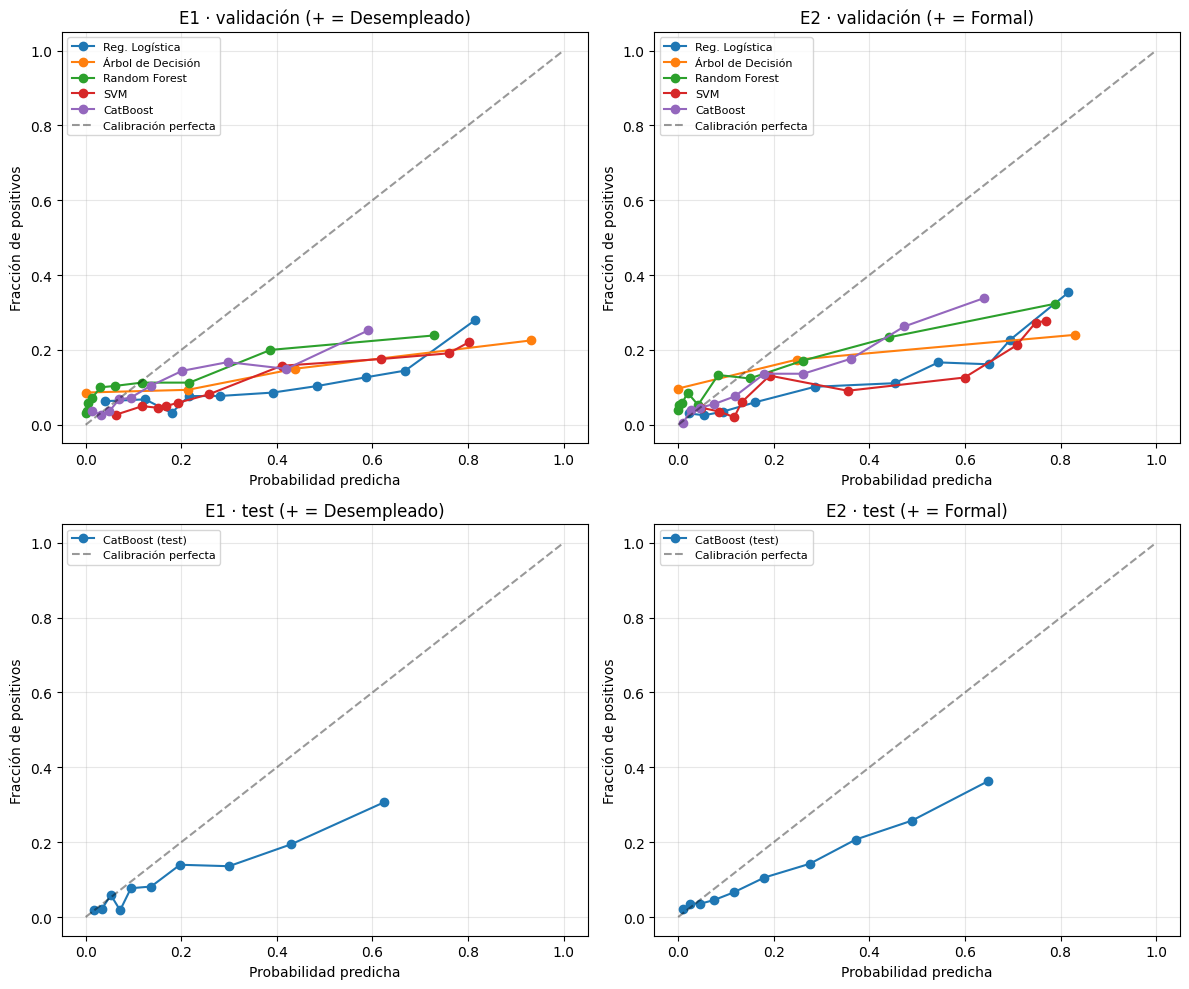

,Etapa,Modelo,Brier,Brier referencia,Brier skill
0,E1 val,Reg. Logística,0.2003,0.0945,-1.1193
1,E1 val,Árbol de Decisión,0.1582,0.0945,-0.6742
2,E1 val,Random Forest,0.1222,0.0945,-0.2925
3,E1 val,SVM,0.1901,0.0945,-1.0111
4,E1 val,CatBoost,0.1112,0.0945,-0.1763
5,E2 val,Reg. Logística,0.1989,0.1111,-0.7909
6,E2 val,Árbol de Decisión,0.1901,0.1111,-0.7115
7,E2 val,Random Forest,0.1340,0.1111,-0.2061
8,E2 val,SVM,0.2062,0.1111,-0.8568
9,E2 val,CatBoost,0.1194,0.1111,-0.0749


In [39]:
def calibracion(probs_dict, ybin, ax, titulo, n_bins=10):
    ref = ybin.mean() * (1 - ybin.mean())
    filas = []
    for n, p in probs_dict.items():
        frac, medio = calibration_curve(ybin, p, n_bins=n_bins, strategy='quantile')
        ax.plot(medio, frac, marker='o', label=n)
        br = brier_score_loss(ybin, p)
        filas.append({'Modelo': n, 'Brier': br, 'Brier referencia': ref, 'Brier skill': 1 - br / ref})
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Calibración perfecta')
    ax.set_xlabel('Probabilidad predicha'); ax.set_ylabel('Fracción de positivos')
    ax.set_title(titulo); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    return filas

pos_test_e1 = {'CatBoost (test)': prob_pos(cat_model_e1, X_test, 'Desempleado')}
ybin_test_e1 = (y_test.values == 'Desempleado').astype(int)
mask_emp_test = (y_test != 'Desempleado').values
X_test_e2 = X_test[mask_emp_test]
pos_test_e2 = {'CatBoost (test)': prob_pos(cat_model_e2, X_test_e2, 'Empleado_Formal')}
ybin_test_e2 = (y_test[mask_emp_test].values == 'Empleado_Formal').astype(int)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
f = []
f += [{'Etapa': 'E1 val', **r} for r in calibracion(pos_val_e1,  ybin_val_e1,  axes[0, 0], 'E1 · validación (+ = Desempleado)')]
f += [{'Etapa': 'E2 val', **r} for r in calibracion(pos_val_e2,  ybin_val_e2,  axes[0, 1], 'E2 · validación (+ = Formal)')]
f += [{'Etapa': 'E1 test', **r} for r in calibracion(pos_test_e1, ybin_test_e1, axes[1, 0], 'E1 · test (+ = Desempleado)')]
f += [{'Etapa': 'E2 test', **r} for r in calibracion(pos_test_e2, ybin_test_e2, axes[1, 1], 'E2 · test (+ = Formal)')]
plt.tight_layout()
plt.savefig('resultados/a2_11_calibracion.png', dpi=150)
plt.show()

tabla_brier = pd.DataFrame(f)
display(tabla_brier.round(4))
tabla_brier.to_csv('resultados/a2_11_brier.csv', index=False)

## 15b. Calibración de probabilidades y niveles de riesgo

Las probabilidades crudas de CatBoost **no están calibradas** (Brier skill < 0 en test) porque el modelo se entrenó con SMOTE-NC, que altera la prevalencia.
Se ajusta un calibrador (Platt o isotónico) **solo con validación**; el método se elige por Brier en validación con validación cruzada y **test se usa una única vez** para reportar.
La regla de clasificación (E1: `predict`, E2: `argmax(proba * peso)`) **no cambia**: la probabilidad calibrada se usa para mostrar riesgo, no para decidir la clase.

Brier CV en validación  E1: {'Platt': np.float64(0.0901), 'Isotónica': np.float64(0.0906)} -> Platt
Brier CV en validación  E2: {'Platt': np.float64(0.1005), 'Isotónica': np.float64(0.1016)} -> Platt


,Etapa,Probabilidad,Brier test,Brier referencia,Brier skill,AUC test,Prob. media,Prevalencia real test
0,E1 (+ = Desempleado),Sin calibrar,0.1065,0.0942,-0.1307,0.7434,0.1960,0.1052
1,E1 (+ = Desempleado),Calibrada (Platt),0.0872,0.0942,0.0743,0.7434,0.1083,0.1052
2,E2 (+ = Formal),Sin calibrar,0.1189,0.1114,-0.0670,0.7643,0.2237,0.1277
3,E2 (+ = Formal),Calibrada (Platt),0.0996,0.1114,0.1060,0.7643,0.1295,0.1277


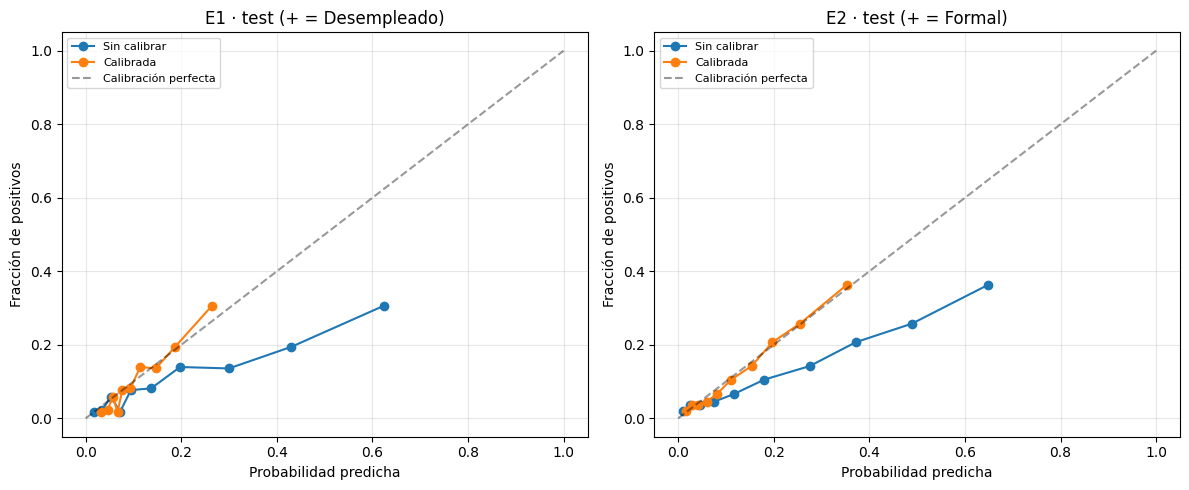

In [40]:
import joblib
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold

def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

class CalibradorPlatt:
    def fit(self, p, y):
        self.lr = LogisticRegression(C=1e6, max_iter=1000).fit(_logit(p), y); return self
    def predict(self, p):
        return self.lr.predict_proba(_logit(p))[:, 1]

class CalibradorIsotonico:
    def fit(self, p, y):
        self.ir = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(p, y); return self
    def predict(self, p):
        return self.ir.predict(p)

METODOS = {'Platt': CalibradorPlatt, 'Isotónica': CalibradorIsotonico}

def brier_cv_val(p, y, clase_cal, n_splits=5):
    # Brier "fuera de muestra" dentro de validación (el calibrador nunca se evalúa con los datos con que se ajusta)
    oof = np.zeros(len(y))
    for tr, te in StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(p, y):
        oof[te] = clase_cal().fit(p[tr], y[tr]).predict(p[te])
    return brier_score_loss(y, oof)

def calibrar_etapa(nombre, p_val, y_val_bin, p_test, y_test_bin):
    base_val  = y_val_bin.mean()
    ref_test  = y_test_bin.mean() * (1 - y_test_bin.mean())
    brier_cv  = {m: brier_cv_val(p_val, y_val_bin, c) for m, c in METODOS.items()}
    mejor     = min(brier_cv, key=brier_cv.get)               # elegido SOLO con validación
    cal       = METODOS[mejor]().fit(p_val, y_val_bin)         # ajuste final con toda la validación
    p_test_cal = cal.predict(p_test)
    filas = []
    for etiqueta, p in (('Sin calibrar', p_test), (f'Calibrada ({mejor})', p_test_cal)):
        br = brier_score_loss(y_test_bin, p)
        filas.append({'Etapa': nombre, 'Probabilidad': etiqueta, 'Brier test': br,
                      'Brier referencia': ref_test, 'Brier skill': 1 - br / ref_test,
                      'AUC test': roc_auc_score(y_test_bin, p), 'Prob. media': p.mean(),
                      'Prevalencia real test': y_test_bin.mean()})
    return cal, mejor, brier_cv, p_test_cal, filas

# Probabilidades crudas (ya calculadas arriba)
p_val_e1_raw  = pos_val_e1['CatBoost'];  p_test_e1_raw = pos_test_e1['CatBoost (test)']
p_val_e2_raw  = pos_val_e2['CatBoost'];  p_test_e2_raw = pos_test_e2['CatBoost (test)']

cal_e1, met_e1, bcv_e1, p_test_e1_cal, f1_rows = calibrar_etapa('E1 (+ = Desempleado)', p_val_e1_raw, ybin_val_e1, p_test_e1_raw, ybin_test_e1)
cal_e2, met_e2, bcv_e2, p_test_e2_cal, f2_rows = calibrar_etapa('E2 (+ = Formal)',      p_val_e2_raw, ybin_val_e2, p_test_e2_raw, ybin_test_e2)
print('Brier CV en validación  E1:', {k: round(v, 4) for k, v in bcv_e1.items()}, '->', met_e1)
print('Brier CV en validación  E2:', {k: round(v, 4) for k, v in bcv_e2.items()}, '->', met_e2)

tabla_calibracion = pd.DataFrame(f1_rows + f2_rows)
display(tabla_calibracion.round(4))
tabla_calibracion.to_csv('resultados/a2_12_calibracion_antes_despues.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (tit, yb, pr, pc) in zip(axes, [('E1 · test (+ = Desempleado)', ybin_test_e1, p_test_e1_raw, p_test_e1_cal),
                                         ('E2 · test (+ = Formal)',      ybin_test_e2, p_test_e2_raw, p_test_e2_cal)]):
    for lab, p in (('Sin calibrar', pr), ('Calibrada', pc)):
        fr, md_ = calibration_curve(yb, p, n_bins=10, strategy='quantile')
        ax.plot(md_, fr, marker='o', label=lab)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Calibración perfecta')
    ax.set_title(tit); ax.set_xlabel('Probabilidad predicha'); ax.set_ylabel('Fracción de positivos')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('resultados/a2_12_calibracion_antes_despues.png', dpi=150); plt.show()

In [41]:
# Niveles de riesgo (bajo / medio / alto): cortes = terciles de la probabilidad calibrada en VALIDACIÓN
NIVELES = ['Bajo', 'Medio', 'Alto']

def cortes_terciles(p_val_cal):
    q = np.quantile(p_val_cal, [1/3, 2/3])
    if q[0] >= q[1]:                       # protección ante empates (p. ej. isotónica)
        q = np.array([q[0], q[0] + 1e-9])
    return [float(q[0]), float(q[1])]

def asignar_nivel(p_cal, cortes):
    return np.where(p_cal < cortes[0], 'Bajo', np.where(p_cal < cortes[1], 'Medio', 'Alto'))

cortes_e1 = cortes_terciles(cal_e1.predict(p_val_e1_raw))
cortes_e2 = cortes_terciles(cal_e2.predict(p_val_e2_raw))

filas = []
for etapa, yb, pc, cortes in (('E1 (+ = Desempleado)', ybin_test_e1, p_test_e1_cal, cortes_e1),
                              ('E2 (+ = Formal)',      ybin_test_e2, p_test_e2_cal, cortes_e2)):
    niv = asignar_nivel(pc, cortes)
    for n in NIVELES:
        m = niv == n
        filas.append({'Etapa': etapa, 'Nivel': n, 'N test': int(m.sum()),
                      'Tasa observada de positivos': float(yb[m].mean()) if m.any() else np.nan,
                      'Prob. calibrada media': float(pc[m].mean()) if m.any() else np.nan})
tabla_niveles = pd.DataFrame(filas)
display(tabla_niveles.round(3))
print('Cortes E1:', [round(c, 3) for c in cortes_e1], '| Cortes E2:', [round(c, 3) for c in cortes_e2])
print('Lectura: la tasa observada debe crecer de Bajo a Alto; si no, los niveles no discriminan.')
tabla_niveles.to_csv('resultados/a2_13_niveles_riesgo_test.csv', index=False)

,Etapa,Nivel,N test,Tasa observada de positivos,Prob. calibrada media
0,E1 (+ = Desempleado),Bajo,722,0.032,0.046
1,E1 (+ = Desempleado),Medio,767,0.080,0.087
2,E1 (+ = Desempleado),Alto,725,0.206,0.193
3,E2 (+ = Formal),Bajo,661,0.032,0.031
4,E2 (+ = Formal),Medio,627,0.075,0.096
5,E2 (+ = Formal),Alto,693,0.267,0.254


Cortes E1: [0.064, 0.119] | Cortes E2: [0.056, 0.153]
Lectura: la tasa observada debe crecer de Bajo a Alto; si no, los niveles no discriminan.


## 16. Exportar mejor modelo entrenado (CatBoost) y calibradores

In [43]:
VERSION = 'v1.1'

cat_model_e1.save_model('modelos/modelo_etapa1_empleo.cbm')
cat_model_e2.save_model('modelos/modelo_etapa2_formalidad.cbm')

config_produccion = {
    'cat_cols': cat_cols,
    'num_cols': num_cols,
    'clases_etapa1': list(cat_model_e1.classes_),
    'clases_etapa2': list(cat_model_e2.classes_),
    'peso_formal_etapa2': float(mejor_peso_formal),
    'version': VERSION,
    'fecha': datetime.date.today().isoformat(),
    'semilla': SEED,
    'imputacion_numericas': {'estrategia': 'mediana de train', 'medianas': medianas_train.to_dict()},
    'winsorizar': bool(WINSORIZAR),
    'limites_winsor': {'inf': lim_inf.to_dict(), 'sup': lim_sup.to_dict()} if WINSORIZAR else None,
    'poblacion_objetivo': {'edad_min': int(df['edad'].min()), 'edad_max': int(df['edad'].max()),
                           'nota': 'Filtro aplicado en la construcción del dataset (no recorte de valores).'},
    'columnas_entrada': list(X_train.columns),
    'nota_preprocesamiento': 'Convertir cat_cols a str antes de predecir. CatBoost usa categóricas nativas: no aplicar scaler ni one-hot.',
    'etapa1': {'archivo': 'modelo_etapa1_empleo.cbm', 'clases': list(cat_model_e1.classes_),
               'regla': 'predict() de CatBoost (clase de mayor probabilidad)',
               'hiperparametros': cat_model_e1.get_params()},
    'etapa2': {'archivo': 'modelo_etapa2_formalidad.cbm', 'clases': clases_e2,
               'regla': 'argmax(proba * pesos)', 'peso_formal': float(mejor_peso_formal),
               'hiperparametros': cat_model_e2.get_params()},
    'calibracion': {
        'etapa1': {'archivo': 'calibrador_etapa1.joblib', 'metodo': met_e1, 'cortes_riesgo': cortes_e1},
        'etapa2': {'archivo': 'calibrador_etapa2.joblib', 'metodo': met_e2, 'cortes_riesgo': cortes_e2},
        'niveles': NIVELES,
        'nota': 'Calibrador ajustado en validación sobre la probabilidad cruda de CatBoost. La clase predicha NO usa la probabilidad calibrada. En la interfaz mostrar nivel de riesgo, no porcentaje.',
    },
    'metricas_test': {'macro_f1_cascada': float(f1_cascada_test),
                      'ic95_bootstrap': list(ic_cascada),
                      'macro_f1_directo_mejor': float(tabla_cascada_vs_directo['macro-F1 test'].iloc[2]),
                      'modelo_directo_mejor': mejor_directo},
    'versiones': {'python': platform.python_version(), 'scikit-learn': sklearn.__version__,
                  'catboost': catboost.__version__, 'pandas': pd.__version__, 'numpy': np.__version__},
}
with open('modelos/config_produccion.json', 'w', encoding='utf-8') as f:
    json.dump(config_produccion, f, ensure_ascii=False, indent=2, default=str)

joblib.dump(cal_e1, 'modelos/calibrador_etapa1.joblib')
joblib.dump(cal_e2, 'modelos/calibrador_etapa2.joblib')

m1 = CatBoostClassifier().load_model('modelos/modelo_etapa1_empleo.cbm')
m2 = CatBoostClassifier().load_model('modelos/modelo_etapa2_formalidad.cbm')
assert np.allclose(m1.predict_proba(X_test), cat_model_e1.predict_proba(X_test))
assert np.allclose(m2.predict_proba(X_test_e2), cat_model_e2.predict_proba(X_test_e2))
print('Modelos serializados y verificados en ./modelos')

for f_ in ('modelo_etapa1_empleo.cbm', 'modelo_etapa2_formalidad.cbm', 'calibrador_etapa1.joblib', 'calibrador_etapa2.joblib', 'config_produccion.json'):
    shutil.copy(f'modelos/{f_}', f'/content/drive/MyDrive/{f_}')

X_test.to_csv('/content/drive/MyDrive/X_test_final.csv', index=False)
y_test.to_csv('/content/drive/MyDrive/y_test_final.csv', index=False)
X_train.to_csv('/content/drive/MyDrive/X_train_final.csv', index=False)

shutil.copytree('resultados', '/content/drive/MyDrive/resultados_empleo', dirs_exist_ok=True)

Modelos serializados y verificados en ./modelos


'/content/drive/MyDrive/resultados_empleo'